255
0
(512, 512)
255
0
(512, 512)


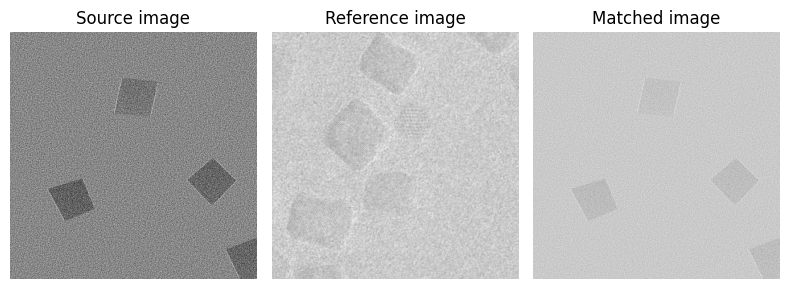

In [1]:
# importing packages 
import matplotlib.pyplot as plt 
from skimage import data 
from skimage import exposure 
from skimage.exposure import match_histograms 
import cv2
import numpy as np

# reading main image 
img1 = cv2.imread("C:\\Users\\Natalia\\OneDrive\\Documents\\TEMapp\\2025051015475020250506172554mary-scott-training3\\train\\0.png") 
img1 = cv2.cvtColor(img1, cv2.COLOR_BGR2GRAY)
print(np.max(img1))
print(np.min(img1))
print(img1.shape)
# reading reference image 
img2 = cv2.imread("C:\\Users\\Natalia\\OneDrive\\Documents\\TEMData\\mary-scott-training\\images\\68.png") 
img2 = cv2.cvtColor(img2, cv2.COLOR_BGR2GRAY)
print(np.max(img2))
print(np.min(img2)) 
print(img2.shape)

# matching histograms 
matched = match_histograms(img1, img2, channel_axis=None) 

fig, (ax1, ax2, ax3) = plt.subplots(nrows=1, 
									ncols=3, 
									figsize=(8, 3), 
									sharex=True, 
									sharey=True) 
for aa in (ax1, ax2, ax3): 
	aa.set_axis_off() 

# displaying images 
ax1.imshow(img1, cmap='gray') 
ax1.set_title('Source image') 
ax2.imshow(img2, cmap='gray') 
ax2.set_title('Reference image') 
ax3.imshow(matched, cmap='gray') 
ax3.set_title('Matched image') 

plt.tight_layout() 
plt.savefig("C:\\Users\\Natalia\\OneDrive\\Documents\\Thesis\\figures\\histogram_matching.png", dpi=300, bbox_inches='tight')
plt.show() 


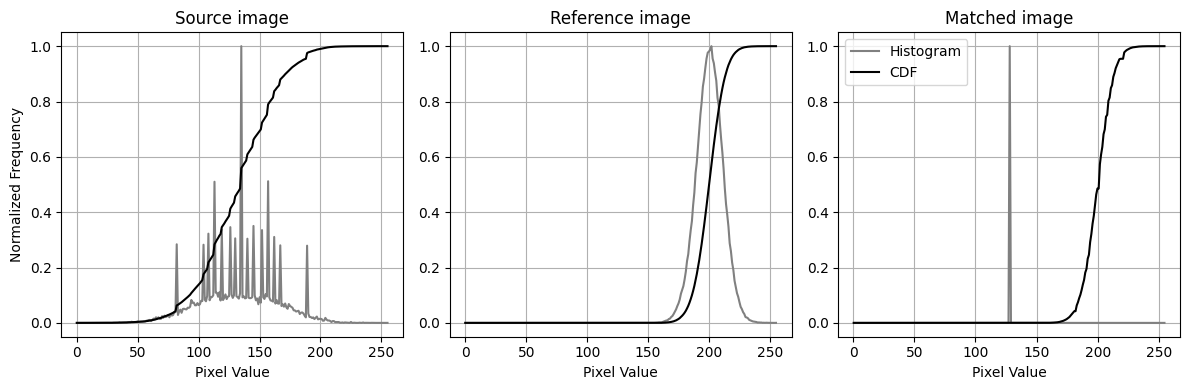

In [29]:
import matplotlib.pyplot as plt
from skimage import exposure

# Create a single row of subplots for grayscale images
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(12, 4))

# Titles for each column
titles = ['Source image', 'Reference image', 'Matched image']

for i, (img, title) in enumerate(zip((img1, img2, matched), titles)):
    # Calculate histogram and CDF for grayscale image
    img_hist, bins = exposure.histogram(img, source_range='dtype')
    img_cdf, bins = exposure.cumulative_distribution(img)
    
    # Plot in single row
    axes[i].plot(bins, img_hist / img_hist.max(), color='gray', label='Histogram')
    axes[i].plot(bins, img_cdf, color='black', label='CDF')
    axes[i].set_title(title)
    axes[i].set_xlabel('Pixel Value')
    axes[i].grid(True)
    
    # Only add y-label to first plot
    if i == 0:
        axes[i].set_ylabel('Normalized Frequency')
        
# Add legend to last subplot
axes[-1].legend()

plt.tight_layout()
plt.show()

In [30]:
#### Apply histogram matching to a percentage of the dataset

In [39]:
import os
import cv2
import numpy as np
import random
import shutil
from tqdm import tqdm

def process_images(input_dir, output_dir, img_ref_path_list, selection_percent=0.1):

    

    # Create output directory if it doesn't exist
    os.makedirs(output_dir, exist_ok=True)
    
    # Get list of all image files
    image_extensions = ('.jpg', '.jpeg', '.png', '.bmp', '.tiff')
    all_images = []

    for count, file in enumerate(os.listdir(input_dir)):
        if file.lower().endswith(image_extensions):
            all_images.append(os.path.join(input_dir, file))

    #root, dirs, files in os.walk(input_dir):
        # for file in files:
        #     if file.lower().endswith(image_extensions):
        #         all_images.append(os.path.join(root, file))
    
    # Select random subset of images to process
    selected_count = max(1, int(len(all_images) * selection_percent))
    selected_images = set(random.sample(all_images, selected_count))
    
    # Process all images
    for img_path in tqdm(all_images, desc="Processing images"):
        try:

            img_ref_path = random.choice(img_ref_path_list)
    
            img_ref = cv2.imread(img_ref_path)

            img_ref = cv2.cvtColor(img_ref, cv2.COLOR_BGR2GRAY)

            # Create relative path for output
            rel_path = os.path.relpath(img_path, input_dir)
            output_path = os.path.join(output_dir, rel_path)
            os.makedirs(os.path.dirname(output_path), exist_ok=True)
            
            if img_path in selected_images:
                # Process selected images with histogram equalization
                img = cv2.imread(img_path)
                if img is None:
                    raise ValueError("Failed to read image")
                
                # Convert to grayscale
                
                img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
                
                # Grayscale image
                processed_img = match_histograms(img, img_ref, channel_axis=None) 
                
                cv2.imwrite(output_path, processed_img)
            else:
                # Copy unselected images directly
                shutil.copy2(img_path, output_path)
            
        except Exception as e:
            print(f"Error processing {img_path}: {str(e)}")
            # Try to copy original as fallback
            try:
                shutil.copy2(img_path, output_path)
            except Exception as copy_error:
                print(f"Failed to copy original: {copy_error}")


# Configuration
INPUT_DIR = "C:\\Users\\Natalia\\OneDrive\\Documents\\TEMapp\\20250510201454\\train"
OUTPUT_DIR = "C:\\Users\\Natalia\\OneDrive\\Documents\\TEMapp\\20250510201454_histogrameq\\"
SELECTION_PERCENTAGE = 0.2  # 20% of images
REFERENCE_IMG = ["C:\\Users\\Natalia\\OneDrive\\Documents\\TEMData\\mary-scott-training\\images\\68.png",
                 "C:\\Users\\Natalia\\OneDrive\\Documents\\TEMData\\mary-scott-training\\images\\194.png"]
# Run processing
process_images(INPUT_DIR, OUTPUT_DIR, REFERENCE_IMG, SELECTION_PERCENTAGE)

print(f"\nProcessed {int(SELECTION_PERCENTAGE*100)}% of images from {INPUT_DIR}")
print(f"All images copied to {OUTPUT_DIR}")

Processing images: 100%|██████████| 1000/1000 [00:05<00:00, 173.96it/s]


Processed 20% of images from C:\Users\Natalia\OneDrive\Documents\TEMapp\20250510201454\train
All images copied to C:\Users\Natalia\OneDrive\Documents\TEMapp\20250510201454_histogrameq\
